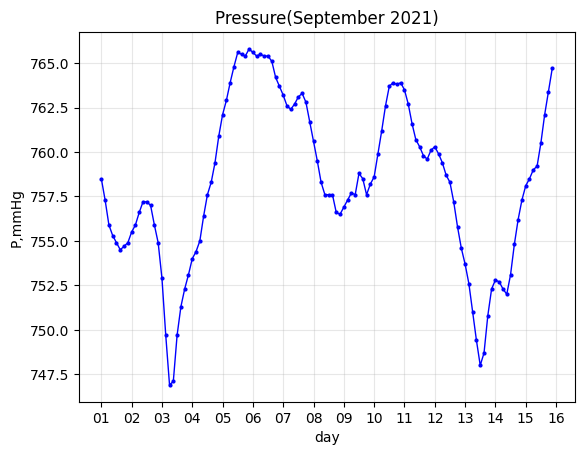

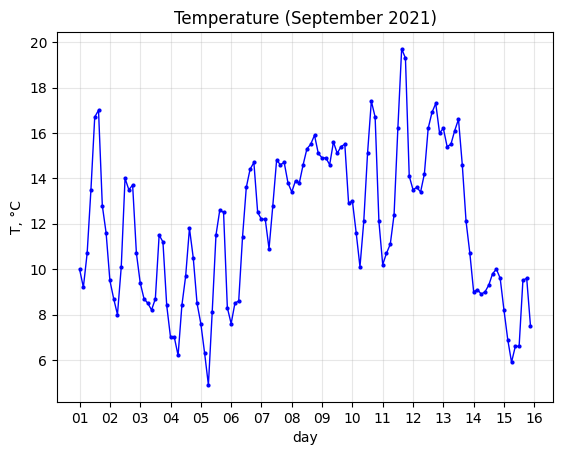

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates 
pu=r"C:\Users\HP Omen\Downloads\September.xlsx"
df = pd.read_excel(pu,sheet_name='Лист1')
df['Time'] = pd.to_datetime(df['Time'])
t = df.iloc[:,0].values
T=df.iloc[:,1].values
P=df.iloc[:,2].values
plt.plot(t,P,'b-o',linewidth=1,markersize=2)
plt.ylabel('P,mmHg')
plt.xlabel('day')
plt.title('Pressure(September 2021)')
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d'))
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=1))
plt.grid(True, alpha=0.3, which='both')
plt.show()
plt.plot(t,T,'b-o',linewidth=1,markersize=2)
plt.ylabel('T, °C')
plt.xlabel('day')
plt.title('Temperature (September 2021)')
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d'))
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=1))
plt.grid(True, alpha=0.3, which='both')
plt.show()

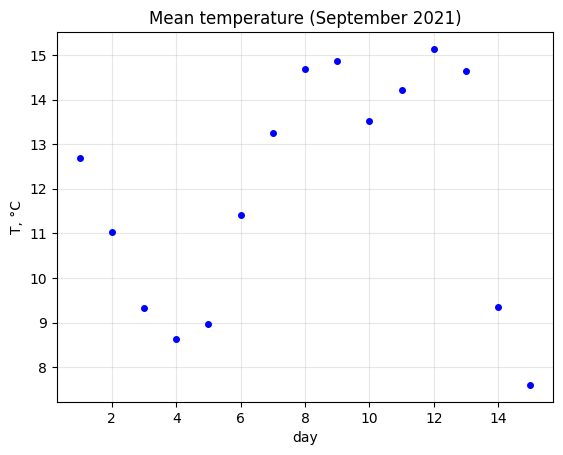

In [29]:
daily = df.groupby(df['Time'].dt.day)['Temperature'].mean()
plt.plot(daily.index, daily.values, 'bo', markersize=4)
plt.ylabel('T, °C')
plt.xlabel('day')
plt.title('Mean temperature (September 2021)')
plt.grid(True, alpha=0.3, which='both')
plt.show()

In [30]:
import xarray as xr
ds = xr.open_dataset(r"C:\Users\HP Omen\Downloads\sst.nc")
print(ds)

<xarray.Dataset> Size: 17MB
Dimensions:  (time: 1, zlev: 1, lat: 720, lon: 1440)
Coordinates:
  * time     (time) datetime64[ns] 8B 1981-09-01T12:00:00
  * zlev     (zlev) float32 4B 0.0
  * lat      (lat) float32 3kB -89.88 -89.62 -89.38 -89.12 ... 89.38 89.62 89.88
  * lon      (lon) float32 6kB 0.125 0.375 0.625 0.875 ... 359.4 359.6 359.9
Data variables:
    anom     (time, zlev, lat, lon) float32 4MB ...
    err      (time, zlev, lat, lon) float32 4MB ...
    ice      (time, zlev, lat, lon) float32 4MB ...
    sst      (time, zlev, lat, lon) float32 4MB ...
Attributes: (12/37)
    title:                      NOAA/NCEI 1/4 Degree Daily Optimum Interpolat...
    source:                     ICOADS, NCEP_GTS, GSFC_ICE, NCEP_ICE, Pathfin...
    id:                         oisst-avhrr-v02r01.19810901.nc
    naming_authority:           gov.noaa.ncei
    summary:                    NOAAs 1/4-degree Daily Optimum Interpolation ...
    cdm_data_type:              Grid
    ...               

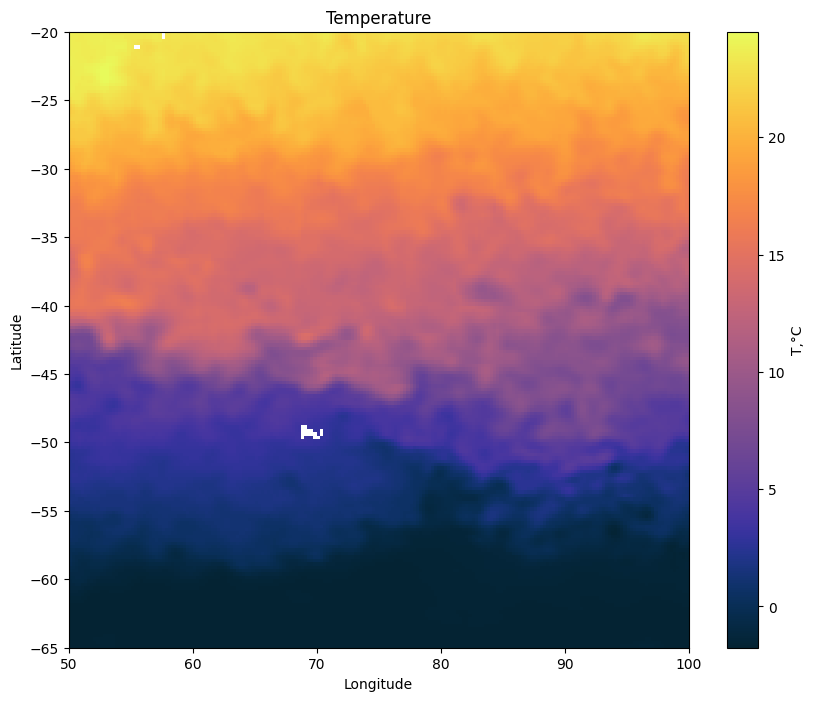

In [31]:
from cmocean import cm
sst_box = ds["sst"].sel(time=ds["time"].values[0],zlev=0.0,lat=slice(-65, -20), lon=slice(50, 100))
plt.figure(figsize=(10, 8))
mesh=plt.pcolormesh(sst_box["lon"],sst_box["lat"],sst_box,cmap="cmo.thermal")
plt.colorbar(mesh,label="T,°C")
plt.ylabel("Latitude")
plt.xlabel("Longitude")
plt.title('Temperature')
plt.show()